# 03 · Integración de fuentes externas


Esta notebook trae las fuentes externas del GCBA (BA Data), las procesa a **nivel de barrio**
y las guarda en `data/external/` para alimentar el análisis avanzado (notebook 04) y la
evaluación de las hipótesis.

**Fuentes integradas:**
- Polígonos de barrios (base geográfica) + población por barrio (Censo)
- Transporte (subte, tren, premetro, Metrobus)
- Delitos (mapa del delito)
- Comercios (habilitaciones / usos del suelo)

**Método:** join espacial (cada punto —estación, delito, comercio— se asigna al barrio cuyo
polígono lo contiene), y luego se agregan los conteos por barrio, normalizados cuando corresponde.

In [1]:
# geopandas no viene en Colab por defecto. Esta celda lo instala.
# (Puede tardar ~1 min. Si ya está instalado, no hace nada.)
!pip install -q geopandas

In [2]:
import subprocess, sys
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

# --- Detección robusta del entorno (mismo patrón que 01 y 02) ---
REPO = "AD_Trabajo_Practico_G6"
cwd = Path.cwd()
if (cwd / "src").exists():
    RAIZ = cwd
elif (cwd.parent / "src").exists():
    RAIZ = cwd.parent
elif (cwd / REPO / "src").exists():
    RAIZ = cwd / REPO
else:
    subprocess.run(["git", "clone", "-q", f"https://github.com/fedelachter/{REPO}"], check=True)
    RAIZ = cwd / REPO
print(f"Raíz del proyecto: {RAIZ}")

# --- Carpeta de salida para las fuentes externas ---
EXTERNAL = RAIZ / "data" / "external"
EXTERNAL.mkdir(parents=True, exist_ok=True)

# --- URLs de las fuentes (centralizadas) ---
URL_BARRIOS = "https://cdn.buenosaires.gob.ar/datosabiertos/datasets/ministerio-de-educacion/barrios/barrios.geojson"

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
print("Setup listo. geopandas versión:", gpd.__version__)

Raíz del proyecto: /content/AD_Trabajo_Practico_G6
Setup listo. geopandas versión: 1.2.0


## 1. Base geográfica: barrios + población

Se cargan los **polígonos de los 48 barrios** de CABA (la base sobre la que se harán todos los
joins espaciales) y la **población por barrio** (para normalizar los delitos por habitante).

Los nombres de barrio se normalizan para que coincidan con los del dataset de propiedades, ya
que el nombre del barrio es la clave de unión entre las fuentes externas y el dataset principal.

> **Nota de reproducibilidad:** se intenta leer primero de la fuente oficial (BA Data). Como ese
> portal puede presentar intermitencias, se define una fuente espejo (GitHub) como respaldo. Una
> vez descargados, los archivos se guardan en `data/external/` para no depender de la conexión en
> ejecuciones futuras.

In [3]:
# --- Polígonos de los 48 barrios de CABA ---
# Se intenta la fuente oficial (BA Data) y, si falla, una fuente espejo (GitHub).
URLS_BARRIOS = [
    "https://cdn.buenosaires.gob.ar/datosabiertos/datasets/ministerio-de-educacion/barrios/barrios.geojson",
    "https://raw.githubusercontent.com/datosgcba/barrios/master/barrios.geojson",
    "https://github.com/martgnz/ba-data/raw/master/barrios/barrios.geojson",
]

barrios = None
for url in URLS_BARRIOS:
    try:
        barrios = gpd.read_file(url)
        print(f"✓ Barrios cargados desde: {url}")
        break
    except Exception as e:
        print(f"✗ Falló {url}  ({type(e).__name__})")

if barrios is None:
    print("\n⚠ No se pudo descargar de ninguna fuente. Ver celda de respaldo manual abajo.")
else:
    print(f"\nCantidad de barrios: {len(barrios)}")
    print("Columnas:", barrios.columns.tolist())
    barrios.head()

✓ Barrios cargados desde: https://cdn.buenosaires.gob.ar/datosabiertos/datasets/ministerio-de-educacion/barrios/barrios.geojson

Cantidad de barrios: 48
Columnas: ['id', 'objeto', 'nombre', 'comuna', 'perimetro_', 'area_metro', 'geometry']


Tipo de objeto: <class 'geopandas.geodataframe.GeoDataFrame'>

Sistema de coordenadas (CRS): EPSG:4326

Primeros barrios:
    id  objeto             nombre  comuna  perimetro_   area_metro
0    1  BARRIO          Agronomia      15     6556.17   2122169.34
1    2  BARRIO            Almagro       5     8537.90   4050752.25
2    3  BARRIO          Balvanera       3     8375.82   4342280.27
3    4  BARRIO           Barracas       4    12844.17   7954579.06
4    5  BARRIO           Belgrano      13    20443.29   8025458.65
5    6  BARRIO            La Boca       4    20074.86   5036358.08
6    7  BARRIO              Boedo       5     6602.51   2609850.88
7    8  BARRIO          Caballito       6    10990.96   6851028.91
8    9  BARRIO          Chacarita      15     7724.85   3115707.11
9   10  BARRIO            Coghlan      12     4627.56   1279951.37
10  11  BARRIO         Colegiales      13     6374.62   2289774.10
11  12  BARRIO       Constitucion       1     6326.84   2101995.00
12  13 

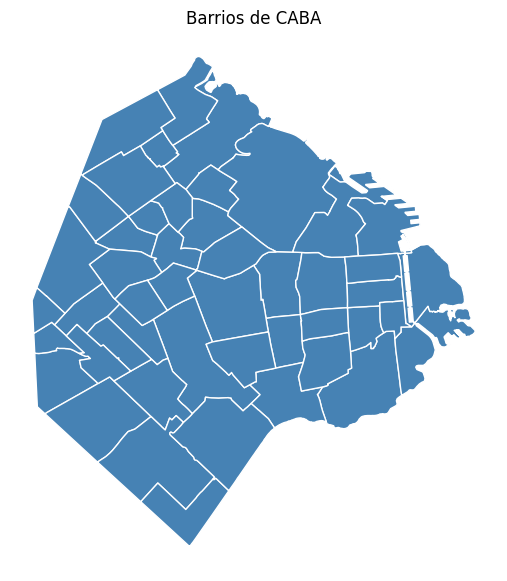

In [4]:
# Ver la estructura del GeoDataFrame: la columna 'geometry' tiene los polígonos
print("Tipo de objeto:", type(barrios))
print("\nSistema de coordenadas (CRS):", barrios.crs)
print("\nPrimeros barrios:")
print(barrios[[c for c in barrios.columns if c != "geometry"]])

# Un mapa rápido para confirmar que son los barrios de CABA
barrios.plot(figsize=(7, 7), edgecolor="white", color="steelblue")
plt.title("Barrios de CABA"); plt.axis("off"); plt.show()

### Población por barrio

El INDEC (Censo 2022) publica la población **solo a nivel comuna**, no por barrio. Como la unidad
de análisis es el **barrio**, se usa una fuente que lo desagrega (citypopulation.de, sobre base
INDEC) y se **valida contra el dato oficial**: la suma de la población de los barrios de cada
comuna debe coincidir con la cifra del INDEC para esa comuna.

- **Fuente de validación (oficial):** INDEC, Censo Nacional 2022 — población por comuna.
  Archivo `c2022_caba_est_c1_1.xlsx` (hoja *Cuadro 1.1*), en `data/external/`.
- **Fuente de desagregación:** citypopulation.de —
  https://www.citypopulation.de/es/argentina/caba/admin/

Se usa la población en **viviendas particulares**, apropiada para medir densidad residencial y
normalizar delitos por habitante.

In [5]:
# --- Población por comuna (INDEC, Censo 2022) — fuente de validación ---
# La columna 3 es la población 2022. Filtramos solo las filas "Comuna N" (con número),
# excluyendo la fila de encabezado que dice solo "Comuna".
ruta_excel = EXTERNAL / "c2022_caba_est_c1_1.xlsx"
raw = pd.read_excel(ruta_excel, sheet_name="Cuadro 1.1", header=None)

# Solo filas cuyo texto en la columna 1 matchea "Comuna" + espacio + número
mask = raw[1].astype(str).str.match(r"Comuna\s+\d+", na=False)
filas = raw[mask].copy()

poblacion_comuna = filas[[1, 3]].copy()
poblacion_comuna.columns = ["comuna", "poblacion_indec"]
poblacion_comuna["poblacion_indec"] = poblacion_comuna["poblacion_indec"].astype(int)
poblacion_comuna["comuna_num"] = poblacion_comuna["comuna"].str.extract(r"(\d+)").astype(int)
poblacion_comuna = poblacion_comuna.sort_values("comuna_num").reset_index(drop=True)

print("Población por comuna (INDEC 2022):")
print(poblacion_comuna[["comuna_num", "poblacion_indec"]].to_string(index=False))
print(f"\nTotal CABA: {poblacion_comuna['poblacion_indec'].sum():,}")

Población por comuna (INDEC 2022):
 comuna_num  poblacion_indec
          1           223554
          2           161645
          3           196240
          4           229240
          5           194271
          6           203043
          7           215896
          8           204367
          9           169063
         10           173004
         11           204601
         12           236887
         13           264385
         14           248635
         15           196876

Total CABA: 3,121,707


In [6]:
# Diagnóstico: ver las filas de comunas con TODAS las columnas
raw = pd.read_excel(ruta_excel, sheet_name="Cuadro 1.1", header=None)
filas = raw[raw[1].astype(str).str.startswith("Comuna", na=False)]
print("Filas de comunas (todas las columnas):")
print(filas.to_string())

Filas de comunas (todas las columnas):
         0          1          2         3                   4                       5
2   Código     Comuna  Población       NaN  Variación absoluta  Variación relativa (%)
5    02007   Comuna 1     205886  223554.0               17668                     8.6
6    02014   Comuna 2     157932  161645.0                3713                     2.4
7    02021   Comuna 3     187537  196240.0                8703                     4.6
8    02028   Comuna 4     218245  229240.0               10995                       5
9    02035   Comuna 5     179005  194271.0               15266                     8.5
10   02042   Comuna 6     176076  203043.0               26967                    15.3
11   02049   Comuna 7     220591  215896.0               -4695                    -2.1
12   02056   Comuna 8     187237  204367.0               17130                     9.1
13   02063   Comuna 9     161797  169063.0                7266                     4.5
14  

### Carga y verificación de la población por barrio

Se carga la población por barrio (citypopulation.de, Censo 2022, viviendas particulares) y se
**valida contra el INDEC**: la suma de la población de los barrios de cada comuna debe aproximarse
a la cifra oficial de esa comuna. Se espera una pequeña diferencia sistemática, porque el total
del INDEC incluye población en viviendas colectivas e institucional, que la cifra por barrio excluye.

In [7]:
# --- Población por barrio (citypopulation, Censo 2022, viviendas particulares) ---
pob_barrio = pd.read_csv(EXTERNAL / "poblacion_barrios.csv")
print(f"Barrios con población: {len(pob_barrio)}  (Agronomía incluye Parque Chas)")

# --- Composición de comunas (de la nota oficial del INDEC) ---
COMUNAS = {
    1: ["Retiro","San Nicolas","Puerto Madero","San Telmo","Montserrat","Constitucion"],
    2: ["Recoleta"],
    3: ["Balvanera","San Cristobal"],
    4: ["La Boca","Barracas","Parque Patricios","Nueva Pompeya"],
    5: ["Almagro","Boedo"],
    6: ["Caballito"],
    7: ["Flores","Parque Chacabuco"],
    8: ["Villa Soldati","Villa Riachuelo","Villa Lugano"],
    9: ["Liniers","Mataderos","Parque Avellaneda"],
    10: ["Villa Real","Monte Castro","Versalles","Floresta","Velez Sarsfield","Villa Luro"],
    11: ["Villa Gral. Mitre","Villa Devoto","Villa del Parque","Villa Santa Rita"],
    12: ["Coghlan","Saavedra","Villa Urquiza","Villa Pueyrredon"],
    13: ["Nuñez","Belgrano","Colegiales"],
    14: ["Palermo"],
    15: ["Chacarita","Villa Crespo","La Paternal","Villa Ortuzar","Agronomia"],  # Agronomía incl. Parque Chas
}

# --- Verificación: suma de barrios por comuna vs. INDEC ---
pob_dict = dict(zip(pob_barrio["barrio"], pob_barrio["poblacion"]))
filas = []
for c, barrios_c in COMUNAS.items():
    suma = sum(pob_dict[b] for b in barrios_c)
    indec = int(poblacion_comuna.loc[poblacion_comuna["comuna_num"] == c, "poblacion_indec"].iloc[0])
    dif_pct = (suma - indec) / indec * 100
    filas.append({"comuna": c, "indec": indec, "suma_barrios": suma,
                  "dif": suma - indec, "dif_%": round(dif_pct, 1),
                  "estado": "OK" if abs(dif_pct) < 2 else "REVISAR"})

verif = pd.DataFrame(filas)
print("\n=== Verificación: suma de barrios vs. INDEC por comuna ===")
print(verif.to_string(index=False))
print(f"\nTodas las comunas dentro del 2% de diferencia: {(verif['estado']=='OK').all()}")
print("La diferencia (~1%, siempre negativa) corresponde a la población en viviendas",
      "colectivas/institucional, incluida en el total INDEC pero no en la cifra por barrio.")

Barrios con población: 47  (Agronomía incluye Parque Chas)

=== Verificación: suma de barrios vs. INDEC por comuna ===
 comuna  indec  suma_barrios   dif  dif_% estado
      1 223554        221001 -2553   -1.1     OK
      2 161645        160609 -1036   -0.6     OK
      3 196240        193537 -2703   -1.4     OK
      4 229240        227024 -2216   -1.0     OK
      5 194271        192449 -1822   -0.9     OK
      6 203043        201764 -1279   -0.6     OK
      7 215896        213262 -2634   -1.2     OK
      8 204367        203888  -479   -0.2     OK
      9 169063        167908 -1155   -0.7     OK
     10 173004        171896 -1108   -0.6     OK
     11 204601        201905 -2696   -1.3     OK
     12 236887        235364 -1523   -0.6     OK
     13 264385        262330 -2055   -0.8     OK
     14 248635        247252 -1383   -0.6     OK
     15 196876        195265 -1611   -0.8     OK

Todas las comunas dentro del 2% de diferencia: True
La diferencia (~1%, siempre negativa) corres

### Separación de Parque Chas

citypopulation agrupa Agronomía y Parque Chas en un solo registro. Como son barrios oficiales
distintos, se separan **estimando la población de cada uno en proporción a su superficie** (dato
del GeoJSON de barrios). Supuesto: ambos barrios tienen densidad poblacional similar (son vecinos
y de perfil residencial parecido).

In [8]:
# --- Separar Parque Chas de Agronomía en proporción a la superficie ---
# Requiere la superficie de ambos, que está en el GeoDataFrame 'barrios' (columna area_metro).
# Ajustá los nombres si en tu GeoJSON difieren (ej. mayúsculas).
area = barrios.set_index("nombre")["area_metro"]

# Buscar los nombres exactos en el GeoJSON (pueden estar en mayúscula u otra forma)
print("Nombres en GeoJSON que contienen 'gron' o 'has':")
print([n for n in barrios["nombre"] if "gron" in n.lower() or "has" in n.lower()])

Nombres en GeoJSON que contienen 'gron' o 'has':
['Agronomia', 'Parque Chas']


In [9]:
# --- Separar Parque Chas de Agronomía en proporción a la superficie ---
# El CSV tiene "Agronomia" con la población combinada (Agronomía + Parque Chas).
# Se reparte según la superficie de cada barrio (area_metro del GeoJSON).
# Supuesto: densidad poblacional similar entre ambos (barrios vecinos y de perfil parecido).

area = barrios.set_index("nombre")["area_metro"]
area_agro = area["Agronomia"]
area_pch = area["Parque Chas"]
pob_combinada = pob_barrio.loc[pob_barrio["barrio"] == "Agronomia", "poblacion"].iloc[0]

# Repartir proporcional a la superficie
pob_agro = round(pob_combinada * area_agro / (area_agro + area_pch))
pob_pch  = pob_combinada - pob_agro   # el resto, para que sumen exactamente el total

# Actualizar Agronomía y agregar Parque Chas
pob_barrio.loc[pob_barrio["barrio"] == "Agronomia", "poblacion"] = pob_agro
pob_barrio = pd.concat([pob_barrio,
                        pd.DataFrame([{"barrio": "Parque Chas", "poblacion": pob_pch}])],
                       ignore_index=True)

print(f"Agronomía: {pob_agro:,}  |  Parque Chas: {pob_pch:,}  (suman {pob_agro + pob_pch:,})")
print(f"Total de barrios ahora: {len(pob_barrio)}")

Agronomía: 19,666  |  Parque Chas: 12,839  (suman 32,505)
Total de barrios ahora: 48


In [10]:
# --- Listado final de población por barrio (los 48) ---
print(f"Total de barrios: {len(pob_barrio)}")
print(f"Población total: {pob_barrio['poblacion'].sum():,}")
print()
print(pob_barrio.sort_values("poblacion", ascending=False).to_string(index=False))

Total de barrios: 48
Población total: 3,095,454

           barrio  poblacion
          Palermo     247252
        Caballito     201764
         Recoleta     160609
           Flores     151440
        Balvanera     143659
          Almagro     142769
         Belgrano     142129
     Villa Lugano     136747
    Villa Urquiza     114293
         Barracas      97982
     Villa Crespo      87877
     Villa Devoto      71602
        Mataderos      67455
           Retiro      67177
            Nuñez      64959
 Parque Chacabuco      61822
 Villa del Parque      61236
       Colegiales      55242
         Saavedra      53665
Parque Avellaneda      53360
    Villa Soldati      51560
    San Cristobal      49878
            Boedo      49680
          Liniers      47093
 Villa Pueyrredon      46603
          La Boca      44205
    Nueva Pompeya      44180
     Constitucion      43838
       Montserrat      41435
 Parque Patricios      40657
         Floresta      36846
      San Nicolas      

### Nota metodológica: diferencia entre población por barrio y por comuna

La suma de la población de los barrios **no coincide exactamente** con el total del INDEC por
comuna, con una diferencia sistemática de aproximadamente **1%** (siempre en el mismo sentido:
la suma por barrio es levemente menor). Esta diferencia **no es un error**, sino la consecuencia
de que ambas cifras miden conceptos distintos:

- **Total INDEC por comuna:** incluye *toda* la población, también la que reside en **viviendas
  colectivas e institucionales** (hospitales, geriátricos, hoteles, establecimientos, personas en
  situación de calle).
- **Población por barrio (citypopulation):** corresponde únicamente a la población en **viviendas
  particulares**, que excluye la institucional.

La diferencia total (~26.000 personas sobre ~3,1 millones) es precisamente la población en
viviendas colectivas de la Ciudad.

**Decisión:** se mantiene la población en **viviendas particulares**, por ser la medida apropiada
para el análisis (densidad residencial y normalización de delitos por habitante). No se fuerza la
coincidencia con el total por comuna, ya que ello implicaría distorsionar el dato correcto —o
introducir un criterio de imputación arbitrario— para igualar un concepto de población distinto.
La verificación por comuna (diferencias < 2% en todos los casos) confirma que la fuente es
consistente con el dato oficial.

## 2. Transporte

Se integran las estaciones de transporte público de CABA (subte, tren, premetro y Metrobus) para
medir el **acceso al transporte de cada barrio**, uno de los componentes del índice de Contexto (H3).

**Método (join espacial):** cada estación es un punto con coordenadas. Mediante un *join espacial*
se asigna cada estación al barrio cuyo polígono la contiene, y luego se cuenta la cantidad de
estaciones por barrio. El conteo se guarda en crudo; la normalización por superficie y la
estandarización se realizan en la notebook de análisis (04).

Fuentes: BA Data (GCBA) — datasets de subte, tren, premetro y Metrobus, en formato GeoJSON.

In [11]:
# --- Estaciones de transporte (subte, tren, premetro, metrobus) ---
# Se intenta cada fuente con respaldo. Cada una es una capa de puntos georreferenciados.
FUENTES_TRANSPORTE = {
    "subte": [
        "https://cdn.buenosaires.gob.ar/datosabiertos/datasets/sbase/subte-estaciones/estaciones-de-subte.geojson",
        "https://raw.githubusercontent.com/martgnz/ba-data/master/subte/estaciones-de-subte.geojson",
    ],
    "metrobus": [
        "https://cdn.buenosaires.gob.ar/datosabiertos/datasets/sbase/estaciones-de-metrobus/estaciones-de-metrobus.geojson",
    ],
}

capas = []
for modo, urls in FUENTES_TRANSPORTE.items():
    for url in urls:
        try:
            g = gpd.read_file(url)
            g["modo"] = modo
            capas.append(g[["modo", "geometry"]])
            print(f"✓ {modo}: {len(g)} estaciones  ({url.split('/')[-1]})")
            break
        except Exception as e:
            print(f"✗ {modo} falló en {url.split('/')[-1]}  ({type(e).__name__})")

if capas:
    transporte = pd.concat(capas, ignore_index=True)
    transporte = gpd.GeoDataFrame(transporte, geometry="geometry", crs=capas[0].crs)
    print(f"\nTotal de puntos de transporte: {len(transporte)}")
    print("CRS:", transporte.crs)
else:
    print("\n⚠ No se pudo cargar ninguna fuente de transporte.")

✓ subte: 90 estaciones  (estaciones-de-subte.geojson)
✗ metrobus falló en estaciones-de-metrobus.geojson  (HTTPError)

Total de puntos de transporte: 90
CRS: EPSG:4326


In [12]:
# --- Asegurar que ambas capas estén en el mismo CRS ---
print("CRS barrios:", barrios.crs)
print("CRS transporte:", transporte.crs)
# Alinear por las dudas (si difieren, reproyecta transporte al CRS de barrios)
if transporte.crs != barrios.crs:
    transporte = transporte.to_crs(barrios.crs)
    print("→ Reproyectado transporte al CRS de barrios")

# --- Join espacial: cada estación -> barrio que la contiene ---
# predicate="within": el punto cae DENTRO del polígono
union = gpd.sjoin(transporte, barrios[["nombre", "geometry"]], how="left", predicate="within")

# --- Contar estaciones por barrio ---
transporte_por_barrio = (union.groupby("nombre").size()
                         .reset_index(name="n_transporte"))

# Asegurar que los 48 barrios aparezcan (los que no tienen estación -> 0)
transporte_por_barrio = (barrios[["nombre"]]
                         .merge(transporte_por_barrio, on="nombre", how="left")
                         .fillna({"n_transporte": 0}))
transporte_por_barrio["n_transporte"] = transporte_por_barrio["n_transporte"].astype(int)

# --- Chequeo: ¿cuántas estaciones quedaron sin asignar? ---
sin_barrio = union["nombre"].isna().sum()
print(f"\nEstaciones asignadas a un barrio: {len(union) - sin_barrio} de {len(union)}")
print(f"Estaciones sin barrio (fuera de CABA o en borde): {sin_barrio}")

print("\nTop 10 barrios por cantidad de estaciones:")
print(transporte_por_barrio.sort_values("n_transporte", ascending=False).head(10).to_string(index=False))

CRS barrios: EPSG:4326
CRS transporte: EPSG:4326

Estaciones asignadas a un barrio: 90 de 90
Estaciones sin barrio (fuera de CABA o en borde): 0

Top 10 barrios por cantidad de estaciones:
       nombre  n_transporte
    Balvanera            12
  San Nicolas            10
    Monserrat             9
     Recoleta             7
      Palermo             6
      Almagro             5
       Flores             5
 Constitucion             5
San Cristobal             5
    Caballito             4


In [13]:
# --- Sumar más modos de transporte: tren y colectivos ---
# Mismo método: cargar puntos, hacer join espacial, contar por barrio.
FUENTES_EXTRA = {
    "tren": [
        "https://cdn.buenosaires.gob.ar/datosabiertos/datasets/sbase/estaciones-ferrocarril/estaciones-ferrocarril.geojson",
        "https://raw.githubusercontent.com/martgnz/ba-data/master/transporte/estaciones-ferrocarril.geojson",
    ],
    "premetro": [
        "https://cdn.buenosaires.gob.ar/datosabiertos/datasets/sbase/estaciones-premetro/estaciones-premetro.geojson",
    ],
    "colectivo": [
        "https://cdn.buenosaires.gob.ar/datosabiertos/datasets/sbase/paradas-de-colectivo/paradas-de-colectivo.geojson",
    ],
}

for modo, urls in FUENTES_EXTRA.items():
    cargado = False
    for url in urls:
        try:
            g = gpd.read_file(url)
            tipo_geom = g.geom_type.iloc[0]   # ver si son Puntos o Líneas
            print(f"✓ {modo}: {len(g)} registros, tipo '{tipo_geom}'  ({url.split('/')[-1]})")
            cargado = True
            break
        except Exception as e:
            print(f"✗ {modo} falló en {url.split('/')[-1]}  ({type(e).__name__})")
    if not cargado:
        print(f"  → {modo}: ninguna fuente disponible")

✗ tren falló en estaciones-ferrocarril.geojson  (HTTPError)
✗ tren falló en estaciones-ferrocarril.geojson  (HTTPError)
  → tren: ninguna fuente disponible
✗ premetro falló en estaciones-premetro.geojson  (HTTPError)
  → premetro: ninguna fuente disponible
✗ colectivo falló en paradas-de-colectivo.geojson  (HTTPError)
  → colectivo: ninguna fuente disponible


In [14]:
# --- Estaciones de ferrocarril (Secretaría de Transporte, 2022) ---
# El CSV cubre todo el AMBA; el join espacial se queda solo con las de CABA.
tren_csv = pd.read_csv(EXTERNAL / "Estacion_ffcc_serv_22.view.csv")
print("Registros totales (AMBA):", len(tren_csv))
print("Columnas:", tren_csv.columns.tolist())

# Convertir las columnas long/lat en geometría de puntos (crear un GeoDataFrame)
# gpd.points_from_xy toma las coordenadas y arma los puntos. CRS 4326 = lat/long estándar.
tren = gpd.GeoDataFrame(
    tren_csv,
    geometry=gpd.points_from_xy(tren_csv["long"], tren_csv["lat"]),
    crs="EPSG:4326",
)

# --- Join espacial: cada estación de tren -> barrio que la contiene ---
# Las que caen fuera de CABA (conurbano) quedan sin barrio y se descartan solas.
tren_union = gpd.sjoin(tren, barrios[["nombre", "geometry"]], how="inner", predicate="within")

tren_por_barrio = (tren_union.groupby("nombre").size()
                   .reset_index(name="n_tren"))

print(f"\nEstaciones de tren DENTRO de CABA: {len(tren_union)} (de {len(tren)} del AMBA)")
print("\nEstaciones de tren por barrio:")
print(tren_por_barrio.sort_values("n_tren", ascending=False).to_string(index=False))

Registros totales (AMBA): 464
Columnas: ['FID', 'id', 'gna', 'nam', 'fna', 'línea', 'caa', 'progresiva', 'fuente', 'geom', 'long', 'lat']

Estaciones de tren DENTRO de CABA: 53 (de 464 del AMBA)

Estaciones de tren por barrio:
          nombre  n_tren
         Palermo       8
          Retiro       5
        Belgrano       4
       Agronomia       2
         Liniers       2
    Constitucion       2
   Villa Soldati       2
        Paternal       2
   Nueva Pompeya       2
           Nuñez       2
       Balvanera       2
       Caballito       2
   Villa Urquiza       2
    Villa Devoto       2
        Floresta       1
          Flores       1
       Chacarita       1
        Barracas       1
         Coghlan       1
      Colegiales       1
    Villa Crespo       1
        Saavedra       1
        Recoleta       1
Villa Del Parque       1
      Villa Luro       1
    Villa Lugano       1
Villa Pueyrredon       1
   Villa Ortuzar       1


In [15]:
# --- Paradas de colectivo (BA Data) ---
# Se usa JOIN ESPACIAL con las coordenadas (no la columna BARRIO del archivo),
# para ser consistentes con el método y garantizar que los nombres coincidan con el GeoJSON.
colectivo_csv = pd.read_csv(EXTERNAL / "paradas-de-colectivo.csv")
print("Paradas totales:", len(colectivo_csv))
print("Columnas:", colectivo_csv.columns.tolist())

# Convertir coord_X (longitud) y coord_Y (latitud) en geometría de puntos
colectivo = gpd.GeoDataFrame(
    colectivo_csv,
    geometry=gpd.points_from_xy(colectivo_csv["coord_X"], colectivo_csv["coord_Y"]),
    crs="EPSG:4326",
)

# --- Join espacial: cada parada -> barrio que la contiene (según los polígonos del GeoJSON) ---
colectivo_union = gpd.sjoin(colectivo, barrios[["nombre", "geometry"]], how="inner", predicate="within")

colectivo_por_barrio = (colectivo_union.groupby("nombre").size()
                        .reset_index(name="n_colectivo"))

# Asegurar que los 48 barrios aparezcan (los que no tengan parada -> 0)
colectivo_por_barrio = (barrios[["nombre"]]
                        .merge(colectivo_por_barrio, on="nombre", how="left")
                        .fillna({"n_colectivo": 0}))
colectivo_por_barrio["n_colectivo"] = colectivo_por_barrio["n_colectivo"].astype(int)

# --- Chequeo ---
sin_barrio = len(colectivo) - len(colectivo_union)
print(f"\nParadas asignadas a un barrio de CABA: {len(colectivo_union)} de {len(colectivo)}")
print(f"Paradas fuera de los polígonos (borde o coordenada inválida): {sin_barrio}")

print("\nParadas de colectivo por barrio (todas, ordenadas):")
print(colectivo_por_barrio.sort_values("n_colectivo", ascending=False).to_string(index=False))

Paradas totales: 7027
Columnas: ['CALLE', 'ALT PLANO', 'DIRECCION', 'coord_X', 'coord_Y', 'COMUNA', 'BARRIO', 'L1', 'l1_sen', 'L2', 'l2_sen', 'L3', 'l3_sen', 'L4', 'l4_sen', 'L5', 'l5_sen', 'L6', 'l6_sen']

Paradas asignadas a un barrio de CABA: 7016 de 7027
Paradas fuera de los polígonos (borde o coordenada inválida): 11

Paradas de colectivo por barrio (todas, ordenadas):
           nombre  n_colectivo
          Palermo          473
        Balvanera          327
         Barracas          308
     Villa Lugano          304
           Flores          291
        Caballito          289
         Recoleta          282
           Retiro          266
         Belgrano          226
    Nueva Pompeya          219
     Constitucion          209
          Almagro          208
        Mataderos          205
      San Nicolas          183
        Monserrat          179
         Saavedra          176
     Villa Crespo          169
     Villa Devoto          166
        Chacarita          157
Par

In [16]:
# --- Consolidar transporte: un registro por barrio con los 3 modos + superficie ---
# Se guardan los conteos EN CRUDO. La densidad (por km²) y el z-score se calculan en la notebook 04.
transporte_barrio = (barrios[["nombre", "area_metro"]]
                     .merge(transporte_por_barrio.rename(columns={"n_transporte": "n_subte"}), on="nombre", how="left")
                     .merge(tren_por_barrio, on="nombre", how="left")
                     .merge(colectivo_por_barrio, on="nombre", how="left"))

# Los barrios sin un modo quedan en 0 (no es NaN: es que no tienen ese transporte)
for col in ["n_subte", "n_tren", "n_colectivo"]:
    transporte_barrio[col] = transporte_barrio[col].fillna(0).astype(int)

# Superficie en km² (el GeoJSON la trae en m²) — insumo para normalizar en la 04
transporte_barrio["area_km2"] = (transporte_barrio["area_metro"] / 1_000_000).round(3)
transporte_barrio = transporte_barrio.drop(columns="area_metro")

print("Transporte consolidado por barrio:")
print(transporte_barrio.sort_values("n_subte", ascending=False).to_string(index=False))

Transporte consolidado por barrio:
           nombre  n_subte  n_tren  n_colectivo  area_km2
        Balvanera       12       2          327     4.342
      San Nicolas       10       0          183     2.289
        Monserrat        9       0          179     2.199
         Recoleta        7       1          282     6.317
          Palermo        6       8          473    15.849
          Almagro        5       0          208     4.051
           Flores        5       1          291     8.591
     Constitucion        5       2          209     2.102
    San Cristobal        5       0          101     2.044
        Caballito        4       2          289     6.851
 Parque Patricios        4       0          144     3.743
           Retiro        4       5          266     4.513
 Parque Chacabuco        3       0          121     3.832
        Chacarita        2       1          157     3.116
         Belgrano        2       4          226     8.025
    Villa Ortuzar        2       1   

## 3. Delitos (seguridad)

Se integran los delitos registrados en CABA para medir la **(in)seguridad de cada barrio**, uno de
los componentes del índice de Contexto (H3). A diferencia de las variables anteriores, este indicador
es **desfavorable** (más delitos = peor contexto), por lo que en la notebook de análisis (04) se
invertirá su signo. Además, el conteo se **normalizará por población** (delitos cada 1.000 habitantes),
para lo cual se usa la población por barrio integrada previamente.

**Método (join espacial):** cada delito es un punto con coordenadas. Mediante un *join espacial* se
asigna cada delito al barrio cuyo polígono lo contiene, y se suma la cantidad de delitos por barrio.
Se consideran **todos los tipos de delito** (robos, hurtos, lesiones, amenazas, vialidad y homicidios)
como medida de inseguridad general del barrio. El conteo se guarda en crudo; la normalización por
población y la estandarización se realizan en la notebook 04.

**Fuente y período:** datos oficiales del Mapa del Delito del GCBA (Ministerio de Justicia y Seguridad,
BA Data), años **2022 y 2023** combinados. Se toma el promedio anual para mayor estabilidad. Se
descartan los delitos sin coordenadas válidas (1,9% del total), que no pueden asignarse a un barrio.



In [17]:
# --- Delitos en CABA (datos oficiales BA Data, 2022 y 2023) ---
ARCHIVOS_DELITOS = ["delitos_2022.csv", "delitos_2023.csv"]

partes = []
for arch in ARCHIVOS_DELITOS:
    d = pd.read_csv(EXTERNAL / arch)
    partes.append(d)
    print(f"✓ {arch}: {len(d):,} delitos")

delitos_raw = pd.concat(partes, ignore_index=True)
print(f"\nTotal combinado (2022+2023): {len(delitos_raw):,} delitos")

# --- Filtrar delitos sin coordenadas válidas (lat/long en 0 o nulas) ---
antes = len(delitos_raw)
delitos_geo = delitos_raw[
    (delitos_raw["latitud"].notna()) & (delitos_raw["longitud"].notna()) &
    (delitos_raw["latitud"] != 0) & (delitos_raw["longitud"] != 0)
].copy()
descartados = antes - len(delitos_geo)

print(f"\nDelitos con coordenadas válidas: {len(delitos_geo):,}")
print(f"Delitos sin geolocalizar (descartados del join): {descartados:,} ({descartados/antes*100:.1f}%)")
print()
print("Tipos de delito:")
print(delitos_geo["tipo"].value_counts().to_string())

✓ delitos_2022.csv: 140,918 delitos
✓ delitos_2023.csv: 155,897 delitos

Total combinado (2022+2023): 296,815 delitos

Delitos con coordenadas válidas: 291,303
Delitos sin geolocalizar (descartados del join): 5,512 (1.9%)

Tipos de delito:
tipo
Robo          120927
Hurto         116500
Lesiones       18420
Vialidad       18124
Amenazas       17154
Homicidios       178


In [18]:
# --- Join espacial: cada delito -> barrio que lo contiene ---
# Convertir las coordenadas en puntos geográficos
delitos_gdf = gpd.GeoDataFrame(
    delitos_geo,
    geometry=gpd.points_from_xy(delitos_geo["longitud"], delitos_geo["latitud"]),
    crs="EPSG:4326",
)

# Join espacial (solo los que caen dentro de un barrio de CABA)
delitos_union = gpd.sjoin(delitos_gdf, barrios[["nombre", "geometry"]], how="inner", predicate="within")

# Contar delitos por barrio (sumando 'cantidad', no solo filas)
delitos_por_barrio = (delitos_union.groupby("nombre")["cantidad"].sum()
                      .reset_index(name="n_delitos"))

# Asegurar los 48 barrios (los que no tengan -> 0)
delitos_por_barrio = (barrios[["nombre"]]
                      .merge(delitos_por_barrio, on="nombre", how="left")
                      .fillna({"n_delitos": 0}))
delitos_por_barrio["n_delitos"] = delitos_por_barrio["n_delitos"].astype(int)

# Como son 2 años (2022+2023), pasamos a promedio anual para que sea interpretable
delitos_por_barrio["n_delitos_anual"] = (delitos_por_barrio["n_delitos"] / 2).round(0).astype(int)

sin_barrio = len(delitos_gdf) - len(delitos_union)
print(f"Delitos asignados a un barrio: {len(delitos_union):,} de {len(delitos_gdf):,}")
print(f"Delitos fuera de los polígonos: {sin_barrio:,}")
print()
print("Delitos (promedio anual) por barrio — top 10 más inseguros:")
print(delitos_por_barrio.sort_values("n_delitos_anual", ascending=False)
      [["nombre", "n_delitos_anual"]].head(10).to_string(index=False))
print()
print("Top 5 más seguros:")
print(delitos_por_barrio.sort_values("n_delitos_anual")
      [["nombre", "n_delitos_anual"]].head(5).to_string(index=False))

Delitos asignados a un barrio: 291,230 de 291,303
Delitos fuera de los polígonos: 73

Delitos (promedio anual) por barrio — top 10 más inseguros:
      nombre  n_delitos_anual
     Palermo            12462
   Balvanera             9664
      Flores             7947
    Recoleta             6664
   Caballito             6278
Villa Lugano             5970
     Almagro             5598
 San Nicolas             5326
    Barracas             4990
    Belgrano             4566

Top 5 más seguros:
       nombre  n_delitos_anual
    Agronomia              488
      Coghlan              558
  Parque Chas              564
Puerto Madero              580
   Villa Real              647


## 4. Comercios (actividad comercial)

Se incorpora la **actividad comercial** de cada barrio como tercer componente del índice de Contexto
(H3), bajo el criterio de que un barrio con mayor oferta comercial ofrece un mejor contexto.

**Fuente:** Mapa de Oportunidades Comerciales (MOC) del GCBA, que registra las aperturas de locales
por **rubro** y por **zona** (`apertura.csv`), junto con la geometría de las zonas (`zonas-moc.geojson`).

**Método.** Las zonas del MOC son más pequeñas que los barrios (161 zonas dentro de los 48 barrios,
construidas sobre radios censales). Por lo tanto, cada zona cae dentro de un barrio: se asigna cada
zona a su barrio mediante join espacial (por el centroide de la zona) y luego se **agregan las
aperturas de todas las zonas de cada barrio**. Esta agregación de lo chico (zona) a lo grande (barrio)
es directa y no requiere repartos ambiguos.

**Supuesto declarado.** La variable mide el **nivel de actividad comercial de la zona**, como proxy
del contexto comercial del barrio. No es un conteo exacto de comercios, sino una referencia construida
a partir de los niveles de apertura registrados por el MOC. Además, la cercanía a zonas comerciales
—aunque estén en el límite del barrio— se considera parte del contexto comercial, en línea con la
lógica de que el acceso a comercios no se limita estrictamente al polígono del barrio.

✓ Zonas cargadas: 161
Columnas: ['zone_id', 'radios', 'geometry']
CRS: EPSG:4326

Primeras filas:
  zone_id  radios
0       1  001_13
1       2  014_10
2       3   015_7
3       4   015_9
4       5   002_1
5       6   004_1
6       7  004_12
7       8  004_18
8       9   004_2
9      10  004_23


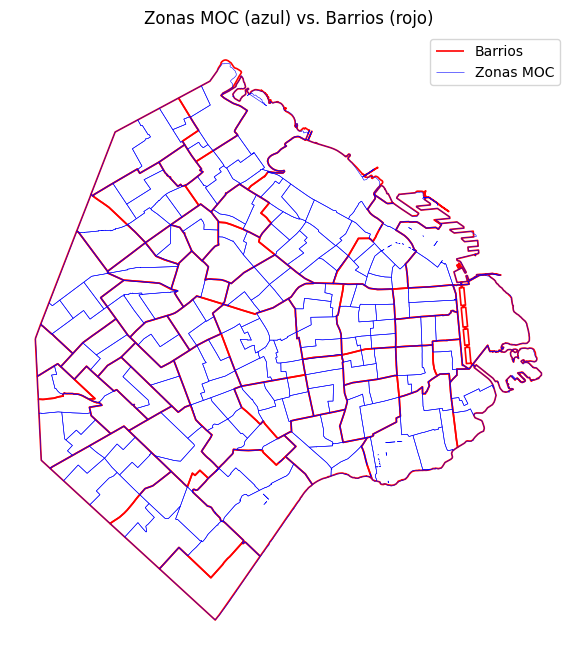

In [19]:
# --- Explorar las zonas del MOC (Mapa de Oportunidades Comerciales) ---
url_zonas = "https://cdn.buenosaires.gob.ar/datosabiertos/datasets/innovacion-transformacion-digital/mapa-oportunidades-comerciales-moc/zonas-moc.geojson"
try:
    zonas = gpd.read_file(url_zonas)
    print(f"✓ Zonas cargadas: {len(zonas)}")
    print("Columnas:", zonas.columns.tolist())
    print("CRS:", zonas.crs)
    print()
    print("Primeras filas:")
    print(zonas.drop(columns="geometry").head(10).to_string())
    # Mapa rápido: ver cómo son las zonas vs. los barrios
    fig, ax = plt.subplots(figsize=(8, 8))
    barrios.boundary.plot(ax=ax, color="red", linewidth=1.2, label="Barrios")
    zonas.boundary.plot(ax=ax, color="blue", linewidth=0.4, label="Zonas MOC")
    ax.set_title("Zonas MOC (azul) vs. Barrios (rojo)"); ax.axis("off"); ax.legend()
    plt.show()
except Exception as e:
    print(f"✗ No se pudo cargar: {type(e).__name__}: {e}")

In [20]:
# --- Asignar cada zona MOC a su barrio (por centroide) ---
# Las zonas son más chicas que los barrios, así que cada zona cae dentro de un barrio.
zonas_c = zonas.copy()
zonas_c["geometry"] = zonas_c.geometry.centroid   # el centro de cada zona
zona_barrio = gpd.sjoin(zonas_c, barrios[["nombre", "geometry"]], how="left", predicate="within")

print("Zonas asignadas a un barrio:", zona_barrio["nombre"].notna().sum(), "de", len(zonas_c))
print("Zonas sin barrio (borde):", zona_barrio["nombre"].isna().sum())
print()

# --- Cargar aperturas y ver la clave ---
aperturas = pd.read_csv(EXTERNAL / "apertura.csv", sep=";")
print("Columnas de aperturas:", aperturas.columns.tolist())
print("Ejemplos de MOC_ZONAS_ID:", sorted(aperturas["MOC_ZONAS_ID"].unique())[:10])
print("Ejemplos de zone_id (geojson):", sorted(zonas["zone_id"].unique())[:10])
print()
print("¿Coinciden las claves? Rango aperturas:",
      aperturas["MOC_ZONAS_ID"].min(), "-", aperturas["MOC_ZONAS_ID"].max(),
      "| Rango zonas:", zonas["zone_id"].min(), "-", zonas["zone_id"].max())

Zonas asignadas a un barrio: 160 de 161
Zonas sin barrio (borde): 1

Columnas de aperturas: ['RUBRO', 'MOC_ZONAS_ID', 'AÑO', 'CUATRIMESTRE', 'NIVEL']
Ejemplos de MOC_ZONAS_ID: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10)]
Ejemplos de zone_id (geojson): ['1', '10', '100', '101', '102', '103', '104', '105', '106', '107']

¿Coinciden las claves? Rango aperturas: 1 - 161 | Rango zonas: 1 - 99


/tmp/ipykernel_1842/1247069725.py:4: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  zonas_c["geometry"] = zonas_c.geometry.centroid   # el centro de cada zona


In [21]:
# --- Asignar cada zona MOC a su barrio (por centroide, en CRS proyectado) ---
# Se reproyecta a un CRS en metros (EPSG:3857) para calcular el centroide correctamente,
# y luego se vuelve a lat/long para el join con los barrios.
zonas_c = zonas.copy()
zonas_c["geometry"] = zonas_c.to_crs(3857).geometry.centroid.to_crs(4326)

zona_barrio = gpd.sjoin(zonas_c, barrios[["nombre", "geometry"]], how="left", predicate="within")
zona_barrio = zona_barrio[["zone_id", "nombre"]].copy()
zona_barrio["zone_id"] = zona_barrio["zone_id"].astype(int)   # a número para cruzar con aperturas

print("Zonas asignadas a un barrio:", zona_barrio["nombre"].notna().sum(), "de", len(zona_barrio))

Zonas asignadas a un barrio: 160 de 161


In [22]:
# --- Agregar las aperturas de cada zona a su barrio ---
aperturas = pd.read_csv(EXTERNAL / "apertura.csv", sep=";")

# Sumar el NIVEL de aperturas por zona (todas las filas de rubros/años de esa zona)
aperturas_x_zona = aperturas.groupby("MOC_ZONAS_ID")["NIVEL"].sum().reset_index(name="nivel_total")

# Unir: zona -> barrio, y sumar por barrio
comercios = (zona_barrio
             .merge(aperturas_x_zona, left_on="zone_id", right_on="MOC_ZONAS_ID", how="left")
             .groupby("nombre")["nivel_total"].sum()
             .reset_index(name="n_comercios"))

# Asegurar los 48 barrios (los que no tengan -> 0)
comercios_por_barrio = (barrios[["nombre"]]
                        .merge(comercios, on="nombre", how="left")
                        .fillna({"n_comercios": 0}))
comercios_por_barrio["n_comercios"] = comercios_por_barrio["n_comercios"].astype(int)

print("Actividad comercial por barrio (suma de niveles de apertura):")
print(comercios_por_barrio.sort_values("n_comercios", ascending=False).to_string(index=False))

Actividad comercial por barrio (suma de niveles de apertura):
           nombre  n_comercios
          Palermo          547
        Caballito          307
        Balvanera          283
         Recoleta          259
         Belgrano          241
           Flores          239
          Almagro          224
      San Nicolas          203
    Villa Urquiza          183
     Villa Crespo          156
     Villa Devoto          144
        Mataderos          135
 Parque Chacabuco          127
        Monserrat          126
 Villa Del Parque          125
          Liniers          124
     Villa Lugano          116
         Barracas           99
         Saavedra           92
         Floresta           91
            Nuñez           90
       Colegiales           89
    Nueva Pompeya           88
     Constitucion           87
            Boedo           81
    San Cristobal           78
 Villa Pueyrredon           78
           Retiro           78
     Monte Castro           76
        

## 5. Consolidación y guardado

Se unen todas las fuentes en una única tabla con **un registro por barrio**, que será el insumo de la
notebook de análisis (04). Las variables se guardan **en crudo** (conteos, superficie, población); la
normalización (por superficie o población), la inversión del signo de seguridad y la estandarización
(z-score) se realizan en la notebook 04.

In [23]:
# --- Corregir nombres de barrio en población para que coincidan con el GeoJSON ---
# Hay diferencias de tipeo/mayúsculas entre el CSV de población y los nombres oficiales del GeoJSON.
correcciones = {
    "Montserrat": "Monserrat",
    "La Paternal": "Paternal",
    "Villa del Parque": "Villa Del Parque",
}
pob_barrio["barrio"] = pob_barrio["barrio"].replace(correcciones)

# Verificar que ahora TODOS los barrios de población existan en el GeoJSON
nombres_geo = set(barrios["nombre"])
sin_match = set(pob_barrio["barrio"]) - nombres_geo
print("Barrios de población que NO matchean con el GeoJSON:", sin_match if sin_match else "ninguno ✓")

Barrios de población que NO matchean con el GeoJSON: ninguno ✓


In [24]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [25]:
 # --- Unir todas las fuentes de contexto en una tabla por barrio ---
contexto = (barrios[["nombre"]]
            .merge(pob_barrio.rename(columns={"barrio": "nombre"}), on="nombre", how="left")
            .merge(transporte_barrio, on="nombre", how="left")
            .merge(delitos_por_barrio[["nombre", "n_delitos_anual"]], on="nombre", how="left")
            .merge(comercios_por_barrio, on="nombre", how="left"))

# Orden lógico de columnas
cols = ["nombre", "poblacion", "area_km2",
        "n_subte", "n_tren", "n_colectivo",   # transporte
        "n_delitos_anual",                     # seguridad
        "n_comercios"]                         # comercios
contexto = contexto[cols]

print("Tabla de contexto por barrio (CRUDO):")
print(contexto.to_string(index=False))
print(f"\nFilas: {len(contexto)} barrios")
print("\nNulos por columna (deberían ser todos 0):")
print(contexto.isna().sum().to_string())

Tabla de contexto por barrio (CRUDO):
           nombre  poblacion  area_km2  n_subte  n_tren  n_colectivo  n_delitos_anual  n_comercios
        Agronomia      19666     2.122        0       2           39              488           31
          Almagro     142769     4.051        5       0          208             5598          224
        Balvanera     143659     4.342       12       2          327             9664          283
         Barracas      97982     7.955        0       1          308             4990           99
         Belgrano     142129     8.025        2       4          226             4566          241
          La Boca      44205     5.036        0       0          145             2397           75
            Boedo      49680     2.610        1       0          114             1957           81
        Caballito     201764     6.851        4       2          289             6278          307
        Chacarita      31321     3.116        2       1          157   

In [26]:
# --- Guardar el dataset consolidado de contexto ---
ruta_salida = EXTERNAL / "contexto_por_barrio.csv"
contexto.to_csv(ruta_salida, index=False, encoding="utf-8-sig")
print(f"✓ Guardado en: {ruta_salida}")
print(f"  {len(contexto)} barrios × {len(contexto.columns)} columnas")

✓ Guardado en: /content/AD_Trabajo_Practico_G6/data/external/contexto_por_barrio.csv
  48 barrios × 8 columnas


## 6. Documentación de fuentes externas

| Fuente | Organismo | Nivel | Período | Variable derivada | Mecanismo de unión |
|---|---|---|---|---|---|
| Polígonos de barrios | BA Data (GCBA) | Barrio | Vigente | Base geográfica, superficie | — |
| Población | citypopulation.de / INDEC | Barrio | Censo 2022 | poblacion | Por nombre de barrio |
| Subte | BA Data (GCBA) | Georreferenciado | Vigente | n_subte | Join espacial (puntos → barrio) |
| Ferrocarril | Secretaría de Transporte | Georreferenciado | 2022 | n_tren | Join espacial (puntos → barrio) |
| Colectivos | BA Data (GCBA) | Georreferenciado | Vigente | n_colectivo | Join espacial (paradas → barrio) |
| Delitos | BA Data (GCBA) | Georreferenciado | 2022-2023 | n_delitos_anual | Join espacial (delitos → barrio) |
| Comercios (MOC) | BA Data (GCBA) | Zona MOC | 2016-… | n_comercios | Zona → barrio (centroide) + agregación |

**Normalizaciones pendientes (notebook 04):** transporte y comercios por superficie; delitos por
población (cada 1.000 hab.); inversión del signo de seguridad; estandarización z-score de todos los
componentes para construir el índice de Contexto.

**Validaciones realizadas:** la población por barrio se validó contra el total del INDEC por comuna
(diferencias < 2%); los joins espaciales asignaron >99% de los puntos en todos los casos; los rankings
resultantes son coherentes con el conocimiento del mercado (barrios céntricos con más transporte y
comercios; distribución de delitos y actividad comercial esperables).